# NILM – Semaine 8 : prix réels de l'électricité et planning du lendemain

**Objectif.** En semaine 4, j'ai montré avec un prix *synthétique* qu'un chauffe-eau et une batterie pilotés selon le prix font baisser la facture. Il reste la tâche « signal de prix et planning simple » du planning. Ce notebook la traite en trois étapes :
1. **de vrais signaux de prix français** : les tarifs EDF en vigueur (Base, Heures creuses, Tempo) avec le vrai calendrier des jours Tempo bleus, blancs et rouges, et le vrai prix horaire du marché (prix *spot* day-ahead de la France) ;
2. **un planificateur du lendemain** : chaque jour, dès que les prix de demain sont connus, il calcule les heures de chauffe du chauffe-eau, les heures de charge et de décharge de la batterie, et l'heure conseillée pour le lave-linge et le lave-vaisselle. Je compare un planificateur **optimal** (programmation linéaire) et des **règles simples** (« les heures les moins chères ») qui pourraient tourner directement dans Home Assistant ou sur le microcontrôleur ;
3. **le message descendant** : le planning est codé en un message MQTT de 32 caractères, envoyé du serveur vers le boîtier par NB-IoT. Je simule ensuite ce que le boîtier fait réellement de ce message, heure par heure, avec la vraie consommation de la maison : c'est le gain qu'on obtiendrait vraiment, et non un plafond théorique.

**Données.**
- Consommation : les vraies mesures UK-DALE de la maison 1 sur la période de test des semaines 3 à 7 (12 novembre 2013 – 28 février 2014, 107 jours complets).
- Prix : ceux de la saison de chauffe **2024-2025** (ou 2025-2026, réglable), alignés jour par jour sur la consommation en gardant le même jour de la semaine (le 12 novembre 2013 et le 12 novembre 2024 sont tous deux des mardis).
- Chauffe-eau et batterie : simulés avec les mêmes paramètres qu'en semaines 4 à 6.

**Sources des prix (téléchargées une seule fois puis gardées dans le dossier `prix/`).**
- Tarifs EDF au 1er août 2026 (délibération CRE du 15 juillet 2026), 6 kVA, TTC.
- Couleurs Tempo : API publique `api-couleur-tempo.fr` (données RTE).
- Prix spot France : API publique d'Energy-Charts (Fraunhofer ISE), en €/MWh. Cette API étant en panne depuis début octobre 2026, le notebook se replie automatiquement sur le fichier horaire européen d'Ember (données ENTSO-E, licence CC-BY-4.0), téléchargé une fois puis gardé dans `prix/`.

Si le téléchargement échoue, le notebook bascule sur des prix synthétiques et le signale clairement : les résultats ne sont alors qu'indicatifs.

## 1. Réglages
- `DATA_DIR` : le dossier UK-DALE déjà utilisé (`house_1/an1`) ;
- `SAISON_PRIX` : la saison de prix utilisée (`"2024-2025"` ou `"2025-2026"`) ;
- `BASE`, `HPHC`, `TEMPO` : les prix TTC du kWh d'EDF au 1er août 2026 (6 kVA). Les heures creuses sont de 22 h à 6 h, et pour Tempo la couleur d'un jour s'applique de 6 h à 6 h le lendemain ;
- `DYN_HORS_ENERGIE` : pour transformer le prix spot en prix payé par un client d'offre dynamique, j'ajoute au spot une part fixe (acheminement TURPE, accise, marge du fournisseur), puis la TVA. **Cette valeur est une hypothèse d'ordre de grandeur**, choisie pour que le prix moyen soit comparable au tarif Base ;
- chauffe-eau et batterie : mêmes paramètres qu'en semaines 4 à 6 ; `BAT_USURE` permet d'ajouter un coût d'usure de la batterie par kWh déchargé (0 par défaut, comme avant) ;
- `CYCLES` : forme simplifiée d'un cycle de lave-linge et de lave-vaisselle (part de l'énergie consommée dans la 1re puis la 2e heure) et heures de départ autorisées ;
- `TOPIC_PLAN` : le sujet MQTT du message descendant.

In [1]:
from pathlib import Path
import json, math, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog

# ================== CHEMINS ==================
DATA_DIR = Path.home() / "Desktop/MASTER/Projet/Modele_IA/house_1/an1"
PRIX_DIR = Path("prix"); PRIX_DIR.mkdir(exist_ok=True)              # cache des prix téléchargés
OUT_DIR = Path("planning_s8"); OUT_DIR.mkdir(exist_ok=True)         # résultats de ce notebook
# ================== CONSOMMATION (identique aux semaines 3 à 7) ==================
MAINS = "aggregate"
APPS = ["fridge", "kettle", "washing_machine", "dishwasher"]
LOAD = ("2013-03-01", "2014-02-28")
TEST_FRAC = 0.30
# ================== PRIX ==================
SAISON_PRIX = "2024-2025"                    # saison Tempo / spot utilisée : "2024-2025" ou "2025-2026"
BASE = 0.2001                                # €/kWh TTC, Tarif Bleu option Base, 6 kVA, 1er août 2026
HPHC = {"HP": 0.2142, "HC": 0.1589}          # Tarif Bleu option Heures creuses
HC_HOURS = [22, 23, 0, 1, 2, 3, 4, 5]        # heures creuses (22 h - 6 h), aussi pour Tempo
TEMPO = {"BLEU": (0.1356, 0.1654), "BLANC": (0.1536, 0.1921), "ROUGE": (0.1615, 0.7295)}   # (HC, HP) €/kWh TTC
ABONNEMENT = {"Base": 190.32, "HP/HC": 190.32, "Tempo": 189.60, "Dynamique": 190.32}         # €/an, 6 kVA (dynamique : hypothèse)
DYN_HORS_ENERGIE = 0.085                     # €/kWh HT ajoutés au spot (TURPE + accise + marge) : HYPOTHÈSE
TVA = 1.20
# ================== CHAUFFE-EAU ET BATTERIE (comme en semaines 4 à 6) ==================
WH_CAP, WH_P, WH_DAY = 7.0, 2.0, 5.0         # kWh stockables, kW de chauffe, kWh d'eau chaude par jour
WH_LOSS, WH_MIN, WH_LOW, WH_END = 0.01, 1.0, 0.75, 0.6
DRAW = np.zeros(24)
for h_, w_ in {6: .10, 7: .20, 8: .10, 12: .05, 13: .05, 18: .10, 19: .15, 20: .10, 21: .10, 22: .05}.items():
    DRAW[h_] = w_ * WH_DAY                    # soutirage d'eau chaude par heure (kWh)
BAT_CAP, BAT_P, BAT_ETA = 5.0, 2.5, 0.95
BAT_SOC_MIN, BAT_START, BAT_END = 0.5, 2.5, 2.5
BAT_USURE = 0.0                              # €/kWh déchargé (usure) : 0 = comme en semaine 6 ; ~0,05-0,10 pour être réaliste
MARGE_REGLE_BAT = 0.05                       # règle simple : on n'utilise la batterie que si l'écart de prix couvre les pertes + 5 %
# ================== APPAREILS DÉCALABLES ==================
DEPARTS = [22] + list(range(0, 22))         # départs autorisés ; à prix égal, le premier de la liste l'emporte (22 h)
CYCLES = {"washing_machine": {"profil": [0.8, 0.2], "departs": DEPARTS},     # 80 % de l'énergie la 1re heure (chauffe)
          "dishwasher":      {"profil": [0.75, 0.25], "departs": DEPARTS}}
SEUIL_CYCLE_KWH = 0.2                        # un jour compte comme « jour de cycle » au-delà de cette énergie
# ================== MESSAGE DESCENDANT ==================
TOPIC_PLAN = "maison/nilm_01/plan"           # publié par le serveur avec retain=1, QoS 1
plt.rcParams["figure.figsize"] = (11, 3.2); plt.rcParams["axes.grid"] = True
print("DATA_DIR :", DATA_DIR, "->", "OK" if (DATA_DIR / "labels.dat").exists() else "labels.dat INTROUVABLE")

DATA_DIR : ~/Desktop/MASTER/Projet/Modele_IA/house_1/an1 -> OK


## 2. Consommation de la maison (vraies mesures)
Je relis les mêmes données qu'en semaine 6 (maison entière + 4 appareils, à la minute, mêmes minutes valides) et je garde la période de test. Je passe au pas **horaire**, celui des prix et du planning, et je ne garde que les jours complets (au plus 2 heures manquantes, comblées par la valeur voisine). J'en tire :
- `base` : la consommation de la maison, en kWh pour chaque heure de chaque jour (hors chauffe-eau et batterie, qui sont simulés) ;
- `E_APP` : l'énergie horaire réellement consommée par le lave-linge et le lave-vaisselle, pour la section 7.

In [2]:
def read_labels(folder):
    labels = {}
    for line in (folder / "labels.dat").read_text().splitlines():
        p = line.split(maxsplit=1)
        if len(p) == 2:
            labels[p[1].strip()] = int(p[0])
    return labels

def read_channel(folder, ch):
    df = pd.read_csv(folder / f"channel_{ch}.dat", sep=r"\s+", header=None, usecols=[0, 1], names=["t", "w"])
    df.index = pd.to_datetime(df["t"], unit="s")
    s = df["w"].astype(float)
    return s[~s.index.duplicated()].sort_index().loc[LOAD[0]:LOAD[1]]

labels = read_labels(DATA_DIR)
series = {n: read_channel(DATA_DIR, labels[n]).resample("1min").mean() for n in [MAINS] + APPS}
data = pd.DataFrame(series)
data = data.loc[:min(s.index.max() for s in series.values())]
data = data.reindex(pd.date_range(data.index.min(), data.index.max(), freq="1min"))
valid = data.notna().all(axis=1).values
T = len(data); i_test = int(T * (1 - TEST_FRAC))

def horaire(col):
    s = pd.Series(np.where(valid, data[col].values, np.nan), index=data.index).iloc[i_test:]
    return s.resample("1h").mean() / 1000.0                       # kWh consommés pendant chaque heure

agg_h = horaire(MAINS)
ok_days = [d for d, x in agg_h.groupby(agg_h.index.date) if len(x) == 24 and x.isna().sum() <= 2]
ok_set = set(ok_days)
agg_h = agg_h[[d in ok_set for d in agg_h.index.date]].ffill().bfill()
hours_idx = agg_h.index
D = len(ok_days)
base = agg_h.values.reshape(D, 24)
E_APP = {a: horaire(a).reindex(hours_idx).fillna(0).values.reshape(D, 24) for a in CYCLES}
print(f"{D} jours complets, du {ok_days[0]} au {ok_days[-1]} ; consommation moyenne {base.sum() / D:.1f} kWh/jour "
      f"(+ {WH_DAY:.0f} kWh/jour d'eau chaude simulée)")
for a in CYCLES:
    print(f"  {a:16s} {E_APP[a].sum():6.1f} kWh sur la période, {(E_APP[a].sum(1) > SEUIL_CYCLE_KWH).sum()} jours avec au moins un cycle")

107 jours complets, du 2013-11-12 au 2014-02-28 ; consommation moyenne 9.3 kWh/jour (+ 5 kWh/jour d'eau chaude simulée)
  washing_machine    80.6 kWh sur la période, 61 jours avec au moins un cycle
  dishwasher         43.9 kWh sur la période, 43 jours avec au moins un cycle


## 3. Prix réels : couleurs Tempo et prix spot
**Alignement des dates.** Chaque jour de consommation de l'hiver 2013-2014 reçoit les prix d'un jour de la saison choisie, décalé d'un nombre entier de semaines : le jour de la semaine est conservé (un lundi reste un lundi), ce qui compte pour Tempo (pas de jour rouge le week-end) et pour le spot (prix plus bas le week-end). Les heures sont des heures locales des deux côtés (heure d'hiver).

**Téléchargement.** Les fonctions ci-dessous interrogent les sources publiques, puis enregistrent le résultat dans `prix/` : les exécutions suivantes relisent ces fichiers sans connexion. Pour le prix spot, j'essaie d'abord l'API d'Energy-Charts (par tranches d'un mois), puis, si elle ne répond pas, le fichier horaire d'Ember : un ZIP de toute l'Europe dont je n'extrais que le fichier de la France. Depuis octobre 2025, le marché français a des prix au quart d'heure, que je moyenne à l'heure.

In [3]:
import ssl
try:                                                   # certificats à jour (évite CERTIFICATE_VERIFY_FAILED sur Mac)
    import certifi; _SSL = ssl.create_default_context(cafile=certifi.where())
except ImportError:
    _SSL = ssl.create_default_context()

def telecharger_json(url, timeout=40):
    req = urllib.request.Request(url, headers={"User-Agent": "projet-M1-ESET-nilm"})
    with urllib.request.urlopen(req, timeout=timeout, context=_SSL) as r:
        return json.loads(r.read().decode("utf-8"))

COULEURS = {1: "BLEU", 2: "BLANC", 3: "ROUGE", "1": "BLEU", "2": "BLANC", "3": "ROUGE",
            "BLEU": "BLEU", "BLANC": "BLANC", "ROUGE": "ROUGE", "BLUE": "BLEU", "WHITE": "BLANC", "RED": "ROUGE"}

def lire_tempo_json(js):
    """Accepte une liste de jours [{dateJour, codeJour}, ...] (ou un dict qui en contient une)."""
    if isinstance(js, dict):
        listes = [v for v in js.values() if isinstance(v, list)]
        js = listes[0] if listes else [js]
    jours = {}
    for it in js:
        d = next((it[k] for k in ("dateJour", "date", "jour", "day") if k in it), None)
        c = next((it[k] for k in ("codeJour", "code", "couleur", "libCouleur", "color") if k in it), None)
        c = COULEURS.get(c if not isinstance(c, str) else c.strip().upper())
        if d is not None and c is not None:
            jours[pd.Timestamp(str(d)[:10])] = c
    return pd.Series(jours, name="couleur").sort_index()

def charger_tempo(saison):
    f = PRIX_DIR / f"tempo_{saison}.csv"
    if f.exists():
        return pd.read_csv(f, parse_dates=["date"]).set_index("date")["couleur"], f"fichier {f}"
    try:
        s = lire_tempo_json(telecharger_json(f"https://www.api-couleur-tempo.fr/api/joursTempo?periode={saison}"))
        if len(s) < 100:
            raise ValueError(f"seulement {len(s)} jours reçus")
        s.rename_axis("date").to_frame().to_csv(f)
        return s, "api-couleur-tempo.fr (enregistré dans prix/)"
    except Exception as e:
        print("Tempo : téléchargement impossible ->", type(e).__name__, e)
        return None, None

def lire_spot_json(js):
    t = pd.to_datetime(js["unix_seconds"], unit="s", utc=True).tz_convert("Europe/Paris").tz_localize(None)
    return pd.Series(js["price"], index=t, dtype=float)

EMBER_ZIP_URL = "https://files.ember-energy.org/public-downloads/price/outputs/european_wholesale_electricity_price_data_hourly.zip"

def lire_ember_csv(f):
    """Fichier horaire d'Ember (une ligne par heure) : on repère la colonne de date (locale de préférence) et celle du prix."""
    df = pd.read_csv(f)
    tcol = next((c for c in df.columns if "local" in c.lower()), None) or \
           next(c for c in df.columns if "date" in c.lower() or "time" in c.lower())
    pcol = next(c for c in df.columns if "price" in c.lower() or "eur" in c.lower())
    t = pd.to_datetime(df[tcol], utc=("utc" in tcol.lower()))
    if t.dt.tz is not None:
        t = t.dt.tz_convert("Europe/Paris").dt.tz_localize(None)
    return pd.Series(df[pcol].astype(float).values, index=t)

def charger_ember(debut, fin):
    """Source de repli : données ENTSO-E compilées par Ember (licence CC-BY-4.0), fichier France extrait du ZIP horaire."""
    import zipfile
    f_fr = next(iter(sorted(PRIX_DIR.glob("*[Ff]rance*.csv"))), None)
    if f_fr is None:
        z = PRIX_DIR / "european_wholesale_electricity_price_data_hourly.zip"
        if not z.exists():
            print("Ember : téléchargement du fichier horaire européen (plusieurs dizaines de Mo, une seule fois)…")
            req = urllib.request.Request(EMBER_ZIP_URL, headers={"User-Agent": "projet-M1-ESET-nilm"})
            with urllib.request.urlopen(req, timeout=600, context=_SSL) as r, open(z, "wb") as out:
                while True:
                    bloc = r.read(1 << 20)
                    if not bloc: break
                    out.write(bloc)
        with zipfile.ZipFile(z) as zf:
            nom = next(n for n in zf.namelist() if "france" in n.lower() and n.lower().endswith(".csv"))
            f_fr = PRIX_DIR / Path(nom).name
            f_fr.write_bytes(zf.read(nom))
    s = lire_ember_csv(f_fr)
    return s[~s.index.duplicated()].sort_index().resample("1h").mean().loc[debut:fin - pd.Timedelta(hours=1)], f_fr.name

def charger_spot(debut, fin):
    f = PRIX_DIR / f"spot_FR_{debut.date()}_{fin.date()}.csv"
    if f.exists():
        return pd.read_csv(f, parse_dates=["time"]).set_index("time")["eur_mwh"], f"fichier {f}"
    s = source = None
    try:                                                  # 1) API Energy-Charts (Fraunhofer ISE)
        morceaux, d0 = [], debut
        while d0 < fin:
            d1 = min(d0 + pd.Timedelta(days=31), fin)
            url = f"https://api.energy-charts.info/price?bzn=FR&start={d0.date()}&end={d1.date()}"
            morceaux.append(lire_spot_json(telecharger_json(url, timeout=20)))
            d0 = d1
        s = pd.concat(morceaux)
        s = s[~s.index.duplicated()].sort_index().resample("1h").mean().loc[debut:fin - pd.Timedelta(hours=1)]
        source = "api.energy-charts.info"
    except Exception as e:
        print("Spot, Energy-Charts indisponible ->", type(e).__name__, e)
    if s is None or s.notna().sum() < 24 * 7:
        try:                                              # 2) Ember (données ENTSO-E)
            s, nom = charger_ember(debut, fin)
            source = f"Ember / ENTSO-E ({nom})"
        except Exception as e:
            print("Spot, Ember indisponible ->", type(e).__name__, e)
            s = None
    if s is None or s.notna().sum() < 24 * 7:
        return None, None
    s.rename("eur_mwh").rename_axis("time").to_frame().to_csv(f)
    return s, source + " (enregistré dans prix/)"

# alignement : même jour de la semaine, décalage d'un nombre entier de semaines
an0 = int(SAISON_PRIX[:4])
cible = pd.Timestamp(year=an0, month=ok_days[0].month, day=ok_days[0].day)
OFFSET = int(round((cible - pd.Timestamp(ok_days[0])).days / 7) * 7)
jours_prix = [pd.Timestamp(d) + pd.Timedelta(days=OFFSET) for d in ok_days]
print(f"décalage : {OFFSET} jours ({OFFSET // 7} semaines) -> prix du {jours_prix[0].date()} au {jours_prix[-1].date()} "
      f"({jours_prix[0].day_name()} = {pd.Timestamp(ok_days[0]).day_name()})")

tempo, SRC_TEMPO = charger_tempo(SAISON_PRIX)
spot, SRC_SPOT = charger_spot(jours_prix[0] - pd.Timedelta(days=1), jours_prix[-1] + pd.Timedelta(days=2))

# --- solutions de secours (résultats alors seulement indicatifs) ---
if tempo is None:
    rng = np.random.default_rng(0)
    semaine = [d for d in jours_prix if d.weekday() < 5 and d.month in (12, 1, 2)]
    rouges = set(rng.choice(len(semaine), 22, replace=False))
    tempo = pd.Series({d: ("ROUGE" if i in rouges else "BLEU") for i, d in enumerate(semaine)})
    reste = [d for d in jours_prix if d not in tempo.index or tempo[d] == "BLEU"]
    for i in rng.choice(len(reste), 43, replace=False):
        if reste[i].weekday() < 6: tempo[reste[i]] = "BLANC"
    tempo = tempo.reindex(pd.date_range(jours_prix[0] - pd.Timedelta(days=1), jours_prix[-1])).fillna("BLEU")
    SRC_TEMPO = "SYNTHÉTIQUE (pas de connexion) : résultats indicatifs"
if spot is None:
    idx = pd.date_range(jours_prix[0] - pd.Timedelta(days=1), jours_prix[-1] + pd.Timedelta(days=1), freq="1h")
    hh = idx.hour.values; rng = np.random.default_rng(1)
    forme = (1 + 0.35 * np.exp(-((hh - 8) / 1.8) ** 2) + 0.60 * np.exp(-((hh - 19) / 2.0) ** 2)
             - 0.30 * np.exp(-((hh - 13.5) / 2.5) ** 2) - 0.25 * np.exp(-((hh - 3.5) / 3.0) ** 2))
    jour_f = np.repeat(np.exp(rng.normal(0, 0.25, len(idx) // 24 + 1)), 24)[:len(idx)]
    spot = pd.Series(100 * forme * jour_f, index=idx)
    SRC_SPOT = "SYNTHÉTIQUE (pas de connexion) : résultats indicatifs"
print("couleurs Tempo :", SRC_TEMPO)
print("prix spot      :", SRC_SPOT)

décalage : 4018 jours (574 semaines) -> prix du 2024-11-12 au 2025-02-28 (Tuesday = Tuesday)
couleurs Tempo : fichier prix/tempo_2024-2025.csv
prix spot      : fichier prix/spot_FR_2024-11-11_2025-03-02.csv


## 4. Les quatre signaux de prix, heure par heure
Pour chaque jour et chaque heure, je calcule le prix payé avec chacune des quatre offres :
- **Base** : prix unique ;
- **HP/HC** : heures creuses de 22 h à 6 h ;
- **Tempo** : 6 prix selon la couleur et l'heure. Les heures de 0 h à 6 h sont des heures creuses **de la couleur de la veille** (le jour Tempo va de 6 h à 6 h) ;
- **Dynamique** : TVA × (prix spot + part hors énergie). Le prix spot peut être négatif certaines heures.

Les couleurs Tempo et le prix spot du lendemain sont publiés la veille (couleur vers 11 h, spot vers 13 h) : le planning de demain peut donc être calculé chaque après-midi avec des prix **connus**, pas prévus.

In [4]:
def couleur(j):
    return tempo.get(pd.Timestamp(j), "BLEU")

def prix_tempo_jour(j):
    veille, jour = couleur(j - pd.Timedelta(days=1)), couleur(j)
    p = np.empty(24)
    for h in range(24):
        if h < 6: p[h] = TEMPO[veille][0]
        elif h >= 22: p[h] = TEMPO[jour][0]
        else: p[h] = TEMPO[jour][1]
    return p

hc_mask = np.isin(np.arange(24), HC_HOURS)
spot_h = spot.reindex(pd.date_range(jours_prix[0], jours_prix[-1] + pd.Timedelta(hours=23), freq="1h")).interpolate(limit_direction="both")
SPOT = np.stack([spot_h.loc[j:j + pd.Timedelta(hours=23)].values for j in jours_prix]) / 1000.0   # (jours, 24) €/kWh
PRICES = {
    "Base": np.full((D, 24), BASE),
    "HP/HC": np.tile(np.where(hc_mask, HPHC["HC"], HPHC["HP"]), (D, 1)),
    "Tempo": np.stack([prix_tempo_jour(j) for j in jours_prix]),
    "Dynamique": TVA * (SPOT + DYN_HORS_ENERGIE),
}
COUL = np.array([couleur(j) for j in jours_prix])
resume_prix = pd.DataFrame({t: {"moyen (€/kWh)": p.mean(), "min": p.min(), "max": p.max(),
                                "coût sans pilotage de la conso UK-DALE (€/jour)": (p * base).sum() / D}
                            for t, p in PRICES.items()}).T
print({c: int((COUL == c).sum()) for c in TEMPO}, "jours Tempo sur la période | spot moyen",
      f"{SPOT.mean() * 1000:.0f} €/MWh, de {SPOT.min() * 1000:.0f} à {SPOT.max() * 1000:.0f} €/MWh")
resume_prix.round(3)

{'BLEU': 48, 'BLANC': 38, 'ROUGE': 21} jours Tempo sur la période | spot moyen 105 €/MWh, de 0 à 473 €/MWh


,moyen (€/kWh),min,max,coût sans pilotage de la conso UK-DALE (€/jour)
Base,0.200,0.200,0.200,1.858
HP/HC,0.196,0.159,0.214,1.872
Tempo,0.239,0.136,0.730,2.373
Dynamique,0.228,0.102,0.670,2.198


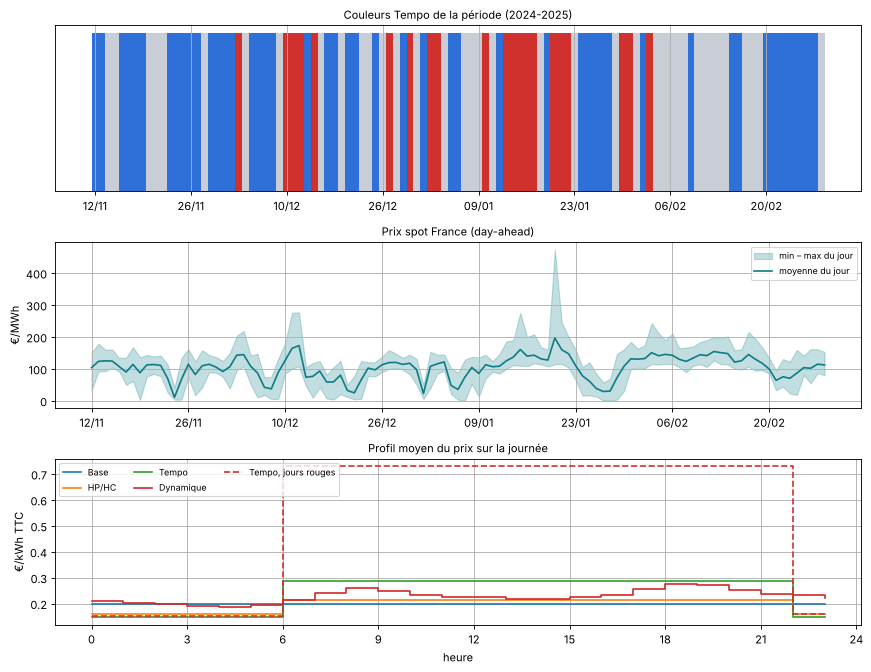

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8.5))
cmap = {"BLEU": "#2E6FD8", "BLANC": "#C9CED6", "ROUGE": "#D0312D"}
axes[0].bar(range(D), np.ones(D), color=[cmap[c] for c in COUL], width=1.0)
axes[0].set_yticks([]); axes[0].set_title(f"Couleurs Tempo de la période ({SAISON_PRIX})", fontsize=10)
axes[0].set_xticks(range(0, D, 14)); axes[0].set_xticklabels([jours_prix[i].strftime("%d/%m") for i in range(0, D, 14)])
jm = SPOT.mean(1) * 1000
axes[1].fill_between(range(D), SPOT.min(1) * 1000, SPOT.max(1) * 1000, color="#0E7C86", alpha=0.25, label="min – max du jour")
axes[1].plot(range(D), jm, color="#0E7C86", label="moyenne du jour")
axes[1].set_ylabel("€/MWh"); axes[1].set_title("Prix spot France (day-ahead)", fontsize=10); axes[1].legend(fontsize=8)
axes[1].set_xticks(range(0, D, 14)); axes[1].set_xticklabels([jours_prix[i].strftime("%d/%m") for i in range(0, D, 14)])
for t, p in PRICES.items():
    axes[2].step(range(24), p.mean(0), where="post", label=t)
for c in ("ROUGE",):
    if (COUL == c).any():
        axes[2].step(range(24), PRICES["Tempo"][COUL == c].mean(0), where="post", ls="--", color="#D0312D", label="Tempo, jours rouges")
axes[2].set_xlabel("heure"); axes[2].set_ylabel("€/kWh TTC"); axes[2].set_xticks(range(0, 25, 3))
axes[2].set_title("Profil moyen du prix sur la journée", fontsize=10); axes[2].legend(fontsize=8, ncol=3, loc="upper left")
plt.tight_layout(); plt.savefig(OUT_DIR / "prix.png", dpi=130); plt.show()

## 5. Le pilotage : optimum, planning du lendemain et règles simples
J'utilise trois façons de décider, de la plus idéale à la plus simple :

1. **Optimum théorique** : un seul programme linéaire sur **tout l'hiver**, qui connaît à l'avance toute la consommation et tous les prix, et choisit librement la puissance de chauffe et de batterie à chaque heure. Aucune stratégie réelle ne peut faire mieux : c'est le **plafond**.
2. **Planning J+1 exécuté** : le programme linéaire de la semaine 4, mais sur **une seule journée** (on ne connaît que les prix de demain) et avec une **prévision** de la consommation (la moyenne des 7 jours précédents, heure par heure). L'énergie qui reste le soir dans la cuve et la batterie est valorisée au prix le plus bas du jour, pour qu'il ne les vide ni ne les remplisse inutilement avant minuit. Son résultat est réduit à ce que le message peut transporter : pour chaque heure, chauffe-eau *autorisé ou non* (le relais), et batterie *en charge, en décharge ou à l'arrêt*. Le boîtier exécute ensuite ces consignes avec la **vraie** consommation : le chauffe-eau chauffe à pleine puissance pendant les heures autorisées jusqu'à ce que la cuve soit pleine (son propre thermostat), la batterie charge ou décharge sans jamais dépasser la consommation de la maison.
3. **Règles simples exécutées** : pas d'optimiseur. Chauffe-eau : j'autorise les heures les moins chères, une par une, jusqu'à ce que la simulation garantisse de l'eau chaude toute la journée. Batterie : charge pendant les heures les moins chères (le temps de la remplir, 2 h), décharge pendant les heures les plus chères, autant qu'il en faut pour couvrir la consommation prévue avec l'énergie stockée, et seulement si l'écart de prix couvre les pertes (+ 5 %). Ces règles tiennent en quelques lignes et peuvent tourner dans Home Assistant, voire sur le microcontrôleur.

Deux références sans pilotage :
- **Thermostat seul** : le chauffe-eau relance dès que la cuve descend sous 75 %, à toute heure (référence des semaines 4 à 6) ;
- **Contacteur HC** : le chauffe-eau n'est alimenté qu'en heures creuses. C'est l'installation la plus courante en France : c'est la **vraie** référence à battre pour un client HP/HC ou Tempo.

Pour chaque jour, l'état de la cuve et de la batterie au matin est celui laissé par la veille. Je compte aussi les **heures d'inconfort** (stock d'eau chaude sous le minimum), qui doivent rester à 0.

In [6]:
def thermostat_day(e0, heating0):
    h = np.zeros(24); e = e0; heating = heating0
    for t in range(24):
        e_pre = max(e * (1 - WH_LOSS) - DRAW[t], 0.0)
        if e_pre < WH_LOW * WH_CAP: heating = True
        if heating:
            h[t] = min(WH_P, WH_CAP - e_pre)
            if e_pre + h[t] >= WH_CAP - 1e-9: heating = False
        e = e_pre + h[t]
    return h, e, heating

def optimise_day(price, base_d, e0, s0, bat_on):
    """Planning d'une journée (programme linéaire sur 24 h). L'énergie restant le soir dans la cuve et la batterie
    est valorisée au prix le plus bas du jour : le programme ne vide ni ne remplit inutilement en fin de journée."""
    n = 24; nv = 5 * n
    ih, ic, idd, ie, isoc = (slice(k * n, (k + 1) * n) for k in range(5))
    cost = np.concatenate([price, price, -price + BAT_USURE, np.zeros(n), np.zeros(n)])
    cost[ie.start + n - 1] = -0.95 * price.min()                     # valeur de l'eau chaude restante
    if bat_on: cost[isoc.start + n - 1] = -BAT_ETA * price.min()      # valeur de l'énergie restant dans la batterie
    Aeq = np.zeros((2 * n, nv)); beq = np.zeros(2 * n)
    for t in range(n):
        Aeq[t, ie.start + t] = 1; Aeq[t, ih.start + t] = -1
        if t > 0: Aeq[t, ie.start + t - 1] = -(1 - WH_LOSS)
        beq[t] = -DRAW[t] + ((1 - WH_LOSS) * e0 if t == 0 else 0)
        r = n + t
        Aeq[r, isoc.start + t] = 1; Aeq[r, ic.start + t] = -BAT_ETA; Aeq[r, idd.start + t] = 1 / BAT_ETA
        if t > 0: Aeq[r, isoc.start + t - 1] = -1
        beq[r] = s0 if t == 0 else 0
    Aub = np.zeros((n, nv)); bub = np.zeros(n)
    for t in range(n):
        Aub[t, idd.start + t] = 1; Aub[t, ih.start + t] = -1; bub[t] = base_d[t]
    b = [(0, WH_P)] * n
    b += [(0, BAT_P) if bat_on else (0, 0) for _ in range(n)] * 2
    b += [(WH_MIN, WH_CAP) for _ in range(n)]
    b += [(BAT_SOC_MIN, BAT_CAP) if bat_on else (s0, s0) for _ in range(n)]
    res = linprog(cost, A_ub=Aub, b_ub=bub, A_eq=Aeq, b_eq=beq, bounds=b, method="highs")
    if res.status != 0: return None
    x = res.x
    return x[ih], x[ic], x[idd], x[ie], x[isoc]

def optimum_global(price, bat_on):
    """Plafond théorique : un seul programme linéaire sur tout l'hiver, qui connaît à l'avance
    toute la consommation et tous les prix (impossible en pratique)."""
    from scipy.sparse import lil_matrix
    n = D * 24; nv = 5 * n
    ih, ic, idd, ie, isoc = (np.arange(k * n, (k + 1) * n) for k in range(5))
    p = price.ravel(); bd = base.ravel(); draw = np.tile(DRAW, D)
    cost = np.concatenate([p, p, -p + BAT_USURE, np.zeros(n), np.zeros(n)])
    Aeq = lil_matrix((2 * n, nv)); beq = np.zeros(2 * n)
    for t in range(n):
        Aeq[t, ie[t]] = 1; Aeq[t, ih[t]] = -1
        if t > 0: Aeq[t, ie[t - 1]] = -(1 - WH_LOSS)
        beq[t] = -draw[t] + ((1 - WH_LOSS) * WH_CAP if t == 0 else 0)
        Aeq[n + t, isoc[t]] = 1; Aeq[n + t, ic[t]] = -BAT_ETA; Aeq[n + t, idd[t]] = 1 / BAT_ETA
        if t > 0: Aeq[n + t, isoc[t - 1]] = -1
        beq[n + t] = BAT_START if (t == 0 and bat_on) else 0
    Aub = lil_matrix((n, nv))
    for t in range(n):
        Aub[t, idd[t]] = 1; Aub[t, ih[t]] = -1
    b = [(0, WH_P)] * n + ([(0, BAT_P)] * n if bat_on else [(0, 0)] * n) * 2
    b += [(WH_MIN, WH_CAP)] * n + ([(BAT_SOC_MIN, BAT_CAP)] * n if bat_on else [(0, 0)] * n)
    res = linprog(cost, A_ub=Aub.tocsr(), b_ub=bd, A_eq=Aeq.tocsr(), b_eq=beq, bounds=b, method="highs")
    if res.status != 0: raise RuntimeError("optimum global : pas de solution")
    x = res.x
    G = (bd + x[ih] + x[ic] - x[idd]).reshape(D, 24)
    return {"G": G, "H": x[ih].reshape(D, 24), "cout": float((G * price).sum() + BAT_USURE * x[idd].sum()),
            "inconfort": 0, "secours": 0, "plans": []}

def executer_jour(autor_ce, modes_bat, base_d, e0, s0, bat_on):
    """Ce que fait le boîtier : relais du chauffe-eau (autorisé / coupé) et mode de la batterie (0 arrêt, 1 charge, 2 décharge)."""
    H, C, Dd, E, S = (np.zeros(24) for _ in range(5)); e, s, inconfort = e0, s0, 0
    for t in range(24):
        e_pre = max(e * (1 - WH_LOSS) - DRAW[t], 0.0)
        if autor_ce[t]: H[t] = min(WH_P, max(0.0, WH_CAP - e_pre))
        e = e_pre + H[t]
        if e < WH_MIN - 1e-3: inconfort += 1      # tolérance : 1 Wh
        if bat_on and modes_bat[t] == 1: C[t] = min(BAT_P, max(0.0, (BAT_CAP - s) / BAT_ETA))
        if bat_on and modes_bat[t] == 2: Dd[t] = min(BAT_P, max(0.0, (s - BAT_SOC_MIN) * BAT_ETA), base_d[t] + H[t])
        s = s + BAT_ETA * C[t] - Dd[t] / BAT_ETA
        E[t], S[t] = e, s
    return {"H": H, "C": C, "D": Dd, "E": E, "S": S, "inconfort": inconfort}

def regle_chauffe_eau(p, e0):
    autor = np.zeros(24, bool)
    for h in np.argsort(p, kind="stable"):
        r = executer_jour(autor, np.zeros(24, int), np.zeros(24), e0, 0.0, False)
        if r["inconfort"] == 0:
            break
        autor[h] = True
    return autor

N_H_BAT = int(math.ceil((BAT_CAP - BAT_SOC_MIN) / BAT_P))          # heures pour remplir la batterie (2)
def regle_batterie(p, conso_prevue):
    modes = np.zeros(24, int)
    bas = np.argsort(p, kind="stable")[:N_H_BAT]                     # heures de charge : les moins chères
    seuil = p[bas].max() * (1 + MARGE_REGLE_BAT)
    stock = (BAT_CAP - BAT_SOC_MIN) * BAT_ETA                         # énergie que la batterie peut rendre
    for h in np.argsort(-p, kind="stable"):                          # heures de décharge : les plus chères d'abord
        if stock <= 0 or p[h] * BAT_ETA ** 2 - BAT_USURE <= seuil or h in bas:
            break
        modes[h] = 2; stock -= min(BAT_P, conso_prevue[h])
    if (modes == 2).any():
        modes[bas] = 1
    return modes

def prevision(k):
    return base[max(0, k - 7):k].mean(0) if k > 0 else base[0]       # moyenne des 7 jours précédents

def simuler(price, mode, bat_on, garder_plans=False):
    e, s, heating = WH_CAP, (BAT_START if bat_on else 0.0), False
    G, H = np.zeros((D, 24)), np.zeros((D, 24)); inconf = secours = 0; plans = []
    if mode == "optimum":
        return optimum_global(price, bat_on)
    for k in range(D):
        p = price[k]; autor = modes = None
        if mode == "thermostat":
            h, e, heating = thermostat_day(e, heating); G[k] = base[k] + h; H[k] = h; continue
        if mode == "plan":
            res = optimise_day(p, prevision(k), e, s, bat_on)
            if res is None:
                secours += 1; autor, modes = hc_mask.copy(), np.zeros(24, int)
            else:
                h, c, d = res[:3]
                autor = h > 1e-6; modes = np.where(c > 0.05, 1, np.where(d > 0.05, 2, 0))
        elif mode == "contacteur":
            autor, modes = hc_mask.copy(), np.zeros(24, int)
        elif mode == "regles":
            autor = regle_chauffe_eau(p, e); modes = regle_batterie(p, prevision(k)) if bat_on else np.zeros(24, int)
        r = executer_jour(autor, modes, base[k], e, s, bat_on)
        G[k] = base[k] + r["H"] + r["C"] - r["D"]; H[k] = r["H"]; e, s = r["E"][-1], r["S"][-1] if bat_on else s
        inconf += r["inconfort"]
        if garder_plans: plans.append((autor.copy(), modes.copy()))
    return {"G": G, "H": H, "cout": float((G * price).sum()), "inconfort": inconf, "secours": secours, "plans": plans}

SCEN = [("1. Thermostat seul", "thermostat", False),
        ("2. Contacteur HC", "contacteur", False),
        ("3. Optimum chauffe-eau", "optimum", False),
        ("4. Optimum chauffe-eau + batterie", "optimum", True),
        ("5. Planning J+1, chauffe-eau", "plan", False),
        ("6. Planning J+1, chauffe-eau + batterie", "plan", True),
        ("7. Règles simples, chauffe-eau", "regles", False),
        ("8. Règles simples, chauffe-eau + batterie", "regles", True)]
sim, rows = {}, []
for tarif, price in PRICES.items():
    for nom, mode, bat in SCEN:
        r = simuler(price, mode, bat, garder_plans=(tarif == "Tempo" and nom.startswith("6")))
        sim[(tarif, nom)] = r
        rows.append({"tarif": tarif, "scénario": nom, "coût (€)": r["cout"], "€/jour": r["cout"] / D,
                     "kWh achetés": r["G"].sum(), "pic horaire (kW)": r["G"].max(),
                     "heures d'inconfort": r["inconfort"], "jours en secours": r["secours"]})
flex = pd.DataFrame(rows).set_index(["tarif", "scénario"])
for ref in ("1. Thermostat seul", "2. Contacteur HC"):
    flex[f"économie vs {ref[3:]} (%)"] = [100 * (1 - flex.loc[(t, s), "coût (€)"] / flex.loc[(t, ref), "coût (€)"]) for t, s in flex.index]
flex.round(2).to_csv(OUT_DIR / "flexibilite_tarifs.csv")
print("heures d'inconfort au total :", int(flex["heures d'inconfort"].sum()), "| jours en secours :", int(flex["jours en secours"].sum()))
flex["€/jour"].unstack("tarif")[list(PRICES)].loc[[s for s, _, _ in SCEN]].round(3)

heures d'inconfort au total : 0 | jours en secours : 0


tarif,Base,HP/HC,Tempo,Dynamique
scénario,,,,
1. Thermostat seul,3.150,3.256,4.218,3.747
2. Contacteur HC,3.085,2.848,3.275,3.551
3. Optimum chauffe-eau,2.896,2.775,3.201,3.245
4. Optimum chauffe-eau + batterie,2.893,2.614,2.687,3.013
"5. Planning J+1, chauffe-eau",3.046,2.823,3.274,3.400
"6. Planning J+1, chauffe-eau + batterie",3.042,2.688,2.819,3.210
"7. Règles simples, chauffe-eau",3.046,2.817,3.249,3.321
"8. Règles simples, chauffe-eau + batterie",3.046,2.674,2.784,3.135


### Lire les résultats
Le tableau ci-dessus donne le **coût de l'électricité par jour** (abonnement non compris) pour chaque offre et chaque façon de piloter. Le tableau suivant donne l'**économie par rapport au contacteur HC**, la référence française. Trois comparaisons m'intéressent :
- **optimum (3, 4) contre planning J+1 exécuté (5, 6)** : ce que coûtent la prévision de consommation et la réduction du planning à un message tout-ou-rien ;
- **planning J+1 (5, 6) contre règles simples (7, 8)** : ce qu'apporte vraiment l'optimiseur ;
- **d'une offre à l'autre** : avec quel tarif le pilotage rapporte le plus. Ici, le choix de l'offre et le pilotage vont ensemble : Tempo n'est intéressant que si l'on évite les heures pleines des jours rouges.

Attention : la période (novembre à février) contient presque tous les jours rouges de la saison. Je ne multiplie donc pas ces chiffres pour obtenir un coût annuel, ce qui surestimerait l'effet des jours rouges.

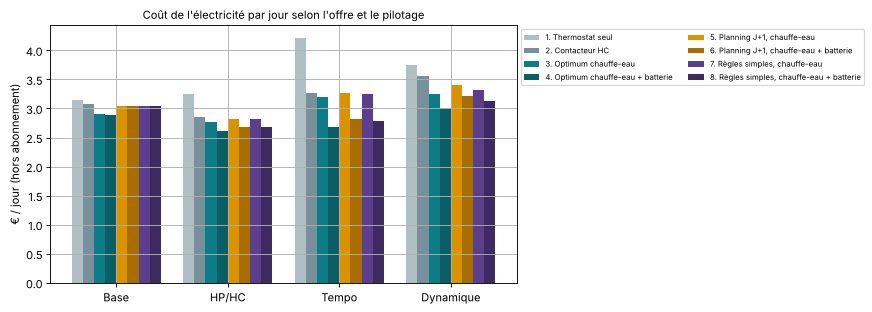

tarif,Base,HP/HC,Tempo,Dynamique
scénario,,,,
1. Thermostat seul,-2.1,-14.3,-28.8,-5.5
2. Contacteur HC,0.0,0.0,0.0,0.0
3. Optimum chauffe-eau,6.1,2.5,2.2,8.6
4. Optimum chauffe-eau + batterie,6.2,8.2,17.9,15.2
"5. Planning J+1, chauffe-eau",1.3,0.9,0.0,4.3
"6. Planning J+1, chauffe-eau + batterie",1.4,5.6,13.9,9.6
"7. Règles simples, chauffe-eau",1.3,1.1,0.8,6.5
"8. Règles simples, chauffe-eau + batterie",1.3,6.1,15.0,11.7


In [7]:
eco = flex["économie vs Contacteur HC (%)"].unstack("tarif")[list(PRICES)].loc[[s for s, _, _ in SCEN]]
display_eco = eco.round(1)
fig, ax = plt.subplots(figsize=(11, 4))
cols = ["#B0BEC5", "#78909C", "#0E7C86", "#0B5E66", "#D99200", "#A86F00", "#5B3F8C", "#3E2A61"]
largeur = 0.1
for i, (nom, _, _) in enumerate(SCEN):
    vals = [flex.loc[(t, nom), "€/jour"] for t in PRICES]
    ax.bar(np.arange(len(PRICES)) + (i - 3.5) * largeur, vals, largeur, color=cols[i], label=nom)
ax.set_xticks(range(len(PRICES))); ax.set_xticklabels(list(PRICES)); ax.set_ylabel("€ / jour (hors abonnement)")
ax.set_title("Coût de l'électricité par jour selon l'offre et le pilotage", fontsize=10)
ax.legend(fontsize=7, ncol=2, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout(); plt.savefig(OUT_DIR / "cout_par_tarif.png", dpi=130, bbox_inches="tight"); plt.show()
display_eco

## 6. Une journée rouge, heure par heure
Pour vérifier que le planning fait des choses sensées, j'affiche le jour **rouge** le plus froid de la période (celui où la maison consomme le plus) avec l'offre Tempo et le planning J+1 chauffe-eau + batterie : prix de chaque heure, heures où le relais du chauffe-eau est fermé et puissance réellement tirée, mode de la batterie et son niveau de charge. On doit voir la chauffe et la charge de la batterie pendant les heures creuses, et la décharge pendant les heures pleines rouges à 0,73 €/kWh.

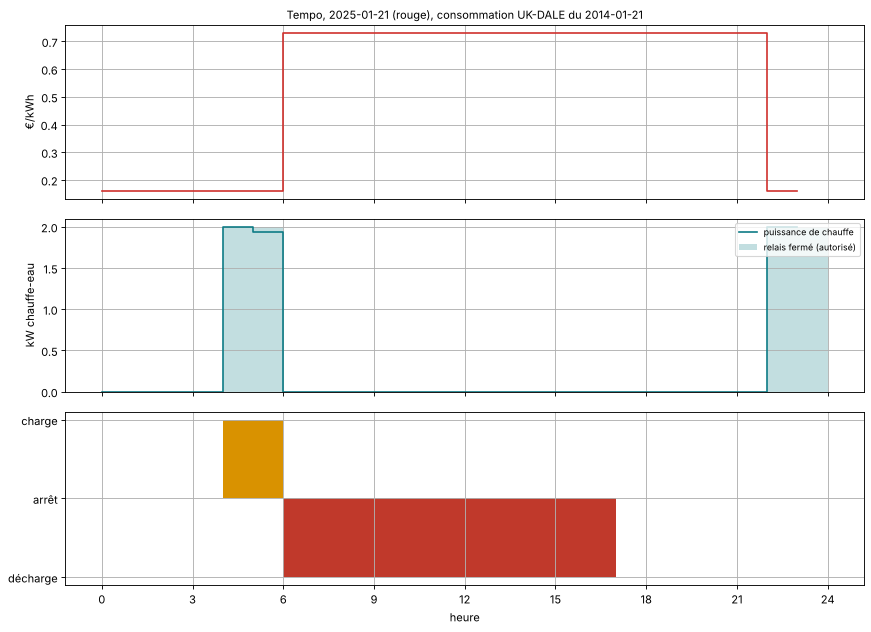

In [8]:
rouges = np.where(COUL == "ROUGE")[0]
k_rouge = int(rouges[np.argmax(base[rouges].sum(1))]) if len(rouges) else int(np.argmax(PRICES["Tempo"].max(1)))
r6 = sim[("Tempo", "6. Planning J+1, chauffe-eau + batterie")]
autor_k, modes_k = r6["plans"][k_rouge]
hh = np.arange(24)
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].step(hh, PRICES["Tempo"][k_rouge], where="post", color="#D0312D"); axes[0].set_ylabel("€/kWh")
axes[0].set_title(f"Tempo, {jours_prix[k_rouge].date()} ({COUL[k_rouge].lower()}), consommation UK-DALE du {ok_days[k_rouge]}", fontsize=10)
axes[1].bar(hh, autor_k * WH_P, width=1, align="edge", color="#0E7C86", alpha=0.25, label="relais fermé (autorisé)")
axes[1].step(hh, r6["H"][k_rouge], where="post", color="#0E7C86", label="puissance de chauffe")
axes[1].set_ylabel("kW chauffe-eau"); axes[1].legend(fontsize=8, loc="upper right")
nets = np.where(modes_k == 1, 1, np.where(modes_k == 2, -1, 0))
axes[2].bar(hh, nets, width=1, align="edge", color=np.where(nets >= 0, "#D99200", "#C0392B"))
axes[2].set_yticks([-1, 0, 1]); axes[2].set_yticklabels(["décharge", "arrêt", "charge"])
axes[2].set_xlabel("heure"); axes[2].set_xticks(range(0, 25, 3))
plt.tight_layout(); plt.savefig(OUT_DIR / "journee_rouge.png", dpi=130); plt.show()

## 7. Appareils décalables : l'heure conseillée
Pour le lave-linge et le lave-vaisselle, le planning donne une **heure de départ conseillée** : celle qui minimise le coût d'un cycle type (80 % ou 75 % de l'énergie la 1re heure, le reste la 2e) parmi les départs autorisés. Pour chaque jour où l'appareil a vraiment tourné (vraies mesures), je compare le coût réel à celui obtenu si le même cycle avait démarré à l'heure conseillée.

Dans le système final, c'est le **NILM** qui fournit cette information sans prise connectée : il sait combien chaque appareil consomme et à quelle heure il est lancé d'habitude, et il permet de **vérifier** après coup que le conseil a été suivi. En semaine 6, l'énergie de ces deux appareils estimée par le réseau était à quelques pour cent de la vraie.

In [9]:
def depart_conseille(p, profil, departs):
    couts = {s: sum(f * p[s + j] for j, f in enumerate(profil)) for s in departs if s + len(profil) <= 24}
    s = min(couts, key=couts.get)
    return s, couts[s]

rows, departs_tempo = [], {}
for tarif, price in PRICES.items():
    for a, cfg in CYCLES.items():
        actuel = decale = 0.0; n = 0; hist = []
        for k in range(D):
            e = E_APP[a][k]
            if e.sum() < SEUIL_CYCLE_KWH: continue
            s, c_unit = depart_conseille(price[k], cfg["profil"], cfg["departs"])
            actuel += (e * price[k]).sum(); decale += e.sum() * c_unit; n += 1; hist.append(s)
        rows.append({"tarif": tarif, "appareil": a, "jours de cycle": n, "coût réel (€)": actuel,
                     "coût à l'heure conseillée (€)": decale, "économie (€)": actuel - decale,
                     "économie (%)": 100 * (1 - decale / actuel) if actuel else np.nan,
                     "heure conseillée la plus fréquente": int(pd.Series(hist).mode()[0]) if hist else None})
        if tarif == "Tempo": departs_tempo[a] = hist
decal = pd.DataFrame(rows).set_index(["tarif", "appareil"])
decal.round(2).to_csv(OUT_DIR / "decalables.csv")
decal.round(2)

jours de cycle  ...  heure conseillée la plus fréquente
tarif     appareil                         ...                                    
Base      washing_machine              61  ...                                  22
          dishwasher                   43  ...                                  22
HP/HC     washing_machine              61  ...                                  22
          dishwasher                   43  ...                                  22
Tempo     washing_machine              61  ...                                  22
          dishwasher                   43  ...                                  22
Dynamique washing_machine              61  ...                                   3
          dishwasher                   43  ...                                   3

[8 rows x 6 columns]

## 8. Le message descendant (serveur → boîtier)
Le planning du lendemain doit tenir dans un message MQTT de **moins de 50 caractères** (limite du module ST87M01). Je propose un format à position fixe de **32 caractères**, publié par le serveur sur `maison/nilm_01/plan` avec *retain* (le boîtier le récupère à son prochain réveil NB-IoT, même s'il dormait au moment de l'envoi) :

```
JJMM;C;RRRRRR;BBBBBBBBBBBB;LL;VV
2101;R;C00030;0002AAAAA500;22;22
```
Exemple ci-dessus (le mardi 21 janvier 2025, jour rouge) : chauffe-eau autorisé de 4 h à 6 h et de 22 h à minuit (`C00030` = bits 4, 5, 22 et 23) ; batterie en charge de 4 h à 6 h (`5` = `01 01` pour les heures 4 et 5) puis en décharge de 6 h à 17 h (`A` = `10 10`), pendant les heures pleines rouges à 0,73 €/kWh ; lave-linge et lave-vaisselle conseillés à 22 h, au début des heures creuses.

| Champ | Taille | Contenu |
|---|---|---|
| `JJMM` | 4 | jour et mois d'application du planning |
| `C` | 1 | couleur Tempo du jour : `B` bleu, `W` blanc, `R` rouge, `-` hors Tempo |
| `RRRRRR` | 6 hex | relais du chauffe-eau : 24 bits, le bit *h* à 1 = chauffe autorisée de *h* h à *h*+1 h |
| `BBBBBBBBBBBB` | 12 hex | batterie : 2 bits par heure (bits 2*h* et 2*h*+1) : 0 arrêt, 1 charge, 2 décharge |
| `LL` | 2 | heure de départ conseillée du lave-linge |
| `VV` | 2 | heure de départ conseillée du lave-vaisselle |

Côté microcontrôleur, le décodage se fait avec deux `strtoul(…, 16)` puis des décalages de bits : `(relais >> h) & 1` et `(batterie >> (2*h)) & 3`. Si aucun planning n'est reçu pour la journée, le boîtier revient à un mode de secours sûr (chauffe-eau autorisé en heures creuses, batterie à l'arrêt).

La cellule suivante code les plannings Tempo de toute la période, vérifie que le décodage redonne exactement le planning et enregistre tous les messages dans `planning_s8/messages_tempo.csv` : la personne A peut les rejouer avec `mosquitto_pub` pour tester la voie descendante dans Home Assistant.

In [10]:
CODE_COULEUR = {"BLEU": "B", "BLANC": "W", "ROUGE": "R"}

def encoder_plan(jour, autor_ce, modes_bat, depart_ll, depart_lv, couleur_jour=None):
    relais = sum(1 << h for h in range(24) if autor_ce[h])
    batt = sum(int(modes_bat[h]) << (2 * h) for h in range(24))
    return (f"{jour.day:02d}{jour.month:02d};{CODE_COULEUR.get(couleur_jour, '-')};"
            f"{relais:06X};{batt:012X};{depart_ll:02d};{depart_lv:02d}")

def decoder_plan(msg):
    jjmm, c, relais, batt, ll, lv = msg.split(";")
    r, b = int(relais, 16), int(batt, 16)
    return {"jour": int(jjmm[:2]), "mois": int(jjmm[2:]), "couleur": c,
            "chauffe_eau": np.array([(r >> h) & 1 for h in range(24)], bool),
            "batterie": np.array([(b >> (2 * h)) & 3 for h in range(24)], int),
            "lave_linge": int(ll), "lave_vaisselle": int(lv)}

msgs = []
for k, (autor, modes) in enumerate(r6["plans"]):
    p = PRICES["Tempo"][k]
    ll = depart_conseille(p, CYCLES["washing_machine"]["profil"], CYCLES["washing_machine"]["departs"])[0]
    lv = depart_conseille(p, CYCLES["dishwasher"]["profil"], CYCLES["dishwasher"]["departs"])[0]
    m = encoder_plan(jours_prix[k], autor, modes, ll, lv, COUL[k])
    dec = decoder_plan(m)
    assert (dec["chauffe_eau"] == autor).all() and (dec["batterie"] == modes).all() and len(m) <= 50
    msgs.append({"jour": jours_prix[k].date(), "couleur": COUL[k], "message": m, "longueur": len(m)})
msgs = pd.DataFrame(msgs)
msgs.to_csv(OUT_DIR / "messages_tempo.csv", index=False)
print(f"{len(msgs)} messages codés et vérifiés (décodage identique), {msgs['longueur'].max()} caractères au plus")
print("exemple (jour rouge) :", msgs.loc[k_rouge, "message"], "| topic :", TOPIC_PLAN)
print(f"commande de test pour A : mosquitto_pub -h <broker> -t {TOPIC_PLAN} -r -q 1 -m '{msgs.loc[k_rouge, 'message']}'")
msgs.groupby("couleur").head(2)

107 messages codés et vérifiés (décodage identique), 32 caractères au plus
exemple (jour rouge) : 2101;R;C00030;0002AAAAA500;22;22 | topic : maison/nilm_01/plan
commande de test pour A : mosquitto_pub -h <broker> -t maison/nilm_01/plan -r -q 1 -m '2101;R;C00030;0002AAAAA500;22;22'


,jour,couleur,message,longueur
0,2024-11-12,BLEU,1211;B;C00000;000002AAA500;22;22,32
1,2024-11-13,BLEU,1311;B;C00020;000002AAA500;22;22,32
2,2024-11-14,BLANC,1411;W;C00020;00000AAAA500;00;00,32
3,2024-11-15,BLANC,1511;W;C00020;0000AAAAA500;22;22,32
21,2024-12-03,ROUGE,0312;R;C00020;0002AAAAA500;00;00,32
28,2024-12-10,ROUGE,1012;R;C00020;0000AAAAA500;00;00,32


## 9. Démonstration : le planning de demain avec les vrais prix
Cette cellule fait ce que fera le serveur chaque après-midi : elle récupère la **couleur Tempo de demain** et le **prix spot de demain**, calcule le planning et affiche le message à publier. Faute de mesures de notre future maison, la consommation prévue est le profil moyen de la maison UK-DALE ; la cuve est supposée au niveau du soir et la batterie à mi-charge. Si les prix de demain ne sont pas encore publiés (couleur avant 11 h environ, spot avant 13 h), ou sans connexion, la cellule le dit simplement.

In [11]:
demain = pd.Timestamp.today().normalize() + pd.Timedelta(days=1)
prevu = base.mean(0)
try:
    js = telecharger_json("https://www.api-couleur-tempo.fr/api/jourTempo/tomorrow")
    c_demain = lire_tempo_json([js]).iloc[0] if len(lire_tempo_json([js])) else None
    js0 = telecharger_json("https://www.api-couleur-tempo.fr/api/jourTempo/today")
    c_auj = lire_tempo_json([js0]).iloc[0] if len(lire_tempo_json([js0])) else "BLEU"
except Exception as e:
    c_demain, c_auj = None, None; print("couleur Tempo de demain indisponible :", type(e).__name__, e)
try:
    s_dem = lire_spot_json(telecharger_json(f"https://api.energy-charts.info/price?bzn=FR&start={demain.date()}&end={(demain + pd.Timedelta(days=1)).date()}"))
    s_dem = s_dem.resample("1h").mean().loc[demain:demain + pd.Timedelta(hours=23)]
    p_dyn_demain = TVA * (s_dem.values / 1000 + DYN_HORS_ENERGIE) if len(s_dem) == 24 else None
except Exception as e:
    p_dyn_demain = None; print("prix spot de demain indisponible :", type(e).__name__, e)

plans_demain = {}
if c_demain in TEMPO:
    p_t = np.array([TEMPO[c_auj or "BLEU"][0] if h < 6 else (TEMPO[c_demain][0] if h >= 22 else TEMPO[c_demain][1]) for h in range(24)])
    plans_demain["Tempo"] = (p_t, c_demain)
if p_dyn_demain is not None:
    plans_demain["Dynamique"] = (p_dyn_demain, None)
for tarif, (p, c) in plans_demain.items():
    res = optimise_day(p, prevu, WH_END * WH_CAP, BAT_START, True)
    autor, modes = (res[0] > 1e-6, np.where(res[1] > 0.05, 1, np.where(res[2] > 0.05, 2, 0))) if res else (hc_mask, np.zeros(24, int))
    ll = depart_conseille(p, CYCLES["washing_machine"]["profil"], CYCLES["washing_machine"]["departs"])[0]
    lv = depart_conseille(p, CYCLES["dishwasher"]["profil"], CYCLES["dishwasher"]["departs"])[0]
    m = encoder_plan(demain, autor, modes, ll, lv, c)
    print(f"{tarif:9s} {demain.date()} {('couleur ' + c.lower()) if c else ''} -> message : {m}  ({len(m)} caractères)")
    print(f"          chauffe autorisée : {[h for h in range(24) if autor[h]]} | charge batterie : {[h for h in range(24) if modes[h] == 1]}"
          f" | décharge : {[h for h in range(24) if modes[h] == 2]} | lave-linge {ll} h, lave-vaisselle {lv} h")
    (OUT_DIR / f"plan_demain_{tarif}.json").write_text(json.dumps({"topic": TOPIC_PLAN, "message": m, "jour": str(demain.date())}, ensure_ascii=False))
if not plans_demain:
    print("Pas de prix de demain disponibles pour l'instant : relancer la cellule après 13 h avec une connexion.")

## 10. Synthèse automatique
Cette cellule résume les chiffres clés de l'exécution (ils servent à rédiger l'analyse et la conclusion).

In [12]:
def eur(t, s): return flex.loc[(t, s), "€/jour"]
lignes = [f"Prix : Tempo {SRC_TEMPO} ; spot {SRC_SPOT} ; saison {SAISON_PRIX} ; {D} jours",
          f"Jours Tempo sur la période : " + ", ".join(f"{c.lower()} {int((COUL == c).sum())}" for c in TEMPO)]
for t in PRICES:
    ref = eur(t, "2. Contacteur HC")
    lignes.append(f"{t:9s} contacteur HC {ref:.2f} €/j | optimum CE+bat {eur(t, '4. Optimum chauffe-eau + batterie'):.2f} | "
                  f"planning J+1 CE {eur(t, '5. Planning J+1, chauffe-eau'):.2f}, CE+bat {eur(t, '6. Planning J+1, chauffe-eau + batterie'):.2f} | "
                  f"règles CE {eur(t, '7. Règles simples, chauffe-eau'):.2f}, CE+bat {eur(t, '8. Règles simples, chauffe-eau + batterie'):.2f} €/j")
reels = flex[[s_[0] in "125678" for _, s_ in flex.index]]["€/jour"]          # stratégies réellement applicables
meilleur = reels.idxmin()
lignes.append(f"Combinaison applicable la moins chère : {meilleur[0]} + {meilleur[1][3:]} ({reels.min():.2f} €/jour, "
              f"contre {flex.loc[('Base', '1. Thermostat seul'), '€/jour']:.2f} €/jour en Base avec un simple thermostat)")
for t in PRICES:
    o = flex.loc[(t, "2. Contacteur HC"), "coût (€)"] - flex.loc[(t, "4. Optimum chauffe-eau + batterie"), "coût (€)"]
    pl = flex.loc[(t, "2. Contacteur HC"), "coût (€)"] - flex.loc[(t, "6. Planning J+1, chauffe-eau + batterie"), "coût (€)"]
    rg = flex.loc[(t, "2. Contacteur HC"), "coût (€)"] - flex.loc[(t, "8. Règles simples, chauffe-eau + batterie"), "coût (€)"]
    if o > 1e-6:
        lignes.append(f"{t:9s} part de l'optimum obtenue : planning J+1 {100 * pl / o:.0f} %, règles simples {100 * rg / o:.0f} %")
for (t, a), r in decal.iterrows():
    lignes.append(f"Décalable {t:9s} {a:16s} : {r['économie (€)']:.2f} € sur la période ({r['économie (%)']:.0f} %), heure conseillée {r['heure conseillée la plus fréquente']} h")
(OUT_DIR / "synthese.txt").write_text("\n".join(lignes), encoding="utf-8")
print("\n".join(lignes))

Prix : Tempo fichier prix/tempo_2024-2025.csv ; spot fichier prix/spot_FR_2024-11-11_2025-03-02.csv ; saison 2024-2025 ; 107 jours
Jours Tempo sur la période : bleu 48, blanc 38, rouge 21
Base      contacteur HC 3.09 €/j | optimum CE+bat 2.89 | planning J+1 CE 3.05, CE+bat 3.04 | règles CE 3.05, CE+bat 3.05 €/j
HP/HC     contacteur HC 2.85 €/j | optimum CE+bat 2.61 | planning J+1 CE 2.82, CE+bat 2.69 | règles CE 2.82, CE+bat 2.67 €/j
Tempo     contacteur HC 3.27 €/j | optimum CE+bat 2.69 | planning J+1 CE 3.27, CE+bat 2.82 | règles CE 3.25, CE+bat 2.78 €/j
Dynamique contacteur HC 3.55 €/j | optimum CE+bat 3.01 | planning J+1 CE 3.40, CE+bat 3.21 | règles CE 3.32, CE+bat 3.13 €/j
Combinaison applicable la moins chère : HP/HC + Règles simples, chauffe-eau + batterie (2.67 €/jour, contre 3.15 €/jour en Base avec un simple thermostat)
Base      part de l'optimum obtenue : planning J+1 22 %, règles simples 20 %
HP/HC     part de l'optimum obtenue : planning J+1 68 %, règles simples 74 %
Tem

## 11. Résultats et analyse
Exécution avec les **vrais prix** de l'hiver 2024-2025 (107 jours, 48 bleus, 38 blancs et 21 rouges ; prix spot moyen de 105 €/MWh, de 0 à 473 €/MWh) et la consommation réelle de la maison UK-DALE, plus un chauffe-eau (5 kWh d'eau chaude par jour) et une batterie de 5 kWh simulés. Aucune heure d'inconfort dans aucun scénario : l'eau chaude est toujours garantie.

**Coût de l'électricité par jour (hors abonnement)**

| Pilotage | Base | HP/HC | Tempo | Dynamique |
|---|---|---|---|---|
| 1. Thermostat seul | 3,15 € | 3,26 € | 4,22 € | 3,75 € |
| 2. Contacteur HC (référence) | 3,09 € | 2,85 € | 3,27 € | 3,55 € |
| 7. Règles simples, chauffe-eau | 3,05 € | 2,82 € | 3,25 € | 3,32 € |
| 8. Règles simples, chauffe-eau + batterie | 3,05 € | **2,67 €** | 2,78 € | 3,13 € |
| 6. Planning J+1 (optimiseur), chauffe-eau + batterie | 3,04 € | 2,69 € | 2,82 € | 3,21 € |
| 4. Optimum théorique, chauffe-eau + batterie | 2,89 € | 2,61 € | 2,69 € | 3,01 € |

**1. Le chauffe-eau seul : le contacteur heures creuses fait déjà presque tout.** Avec les offres HP/HC et Tempo, le piloter heure par heure ne rapporte que 1 % de plus que le contacteur HC (2,5 % au mieux pour l'optimum théorique). En revanche, un chauffe-eau sur simple thermostat coûte 14 % (HP/HC) à 29 % (Tempo) de plus : le vrai gain est d'**éviter les heures pleines**, ce que le contacteur fait déjà. Le pilotage fin du chauffe-eau ne devient intéressant qu'avec le **prix dynamique** (6,5 % d'économie avec les règles simples, 8,6 % pour l'optimum), car les heures bon marché ne sont pas toujours la nuit (creux de mi-journée, prix proches de 0 certains jours).

**2. La batterie fait la différence, surtout avec Tempo.** Ajouter la batterie de 5 kWh fait gagner 6 % en HP/HC, 12 % avec le prix dynamique et **15 % avec Tempo** par rapport au contacteur HC : elle évite d'acheter de l'électricité à 0,73 €/kWh pendant les heures pleines des jours rouges. Sur l'hiver, cela représente environ 50 € avec Tempo. Ce chiffre ne compte ni le prix d'achat de la batterie (plusieurs milliers d'euros) ni son usure (`BAT_USURE` = 0) : la batterie seule n'est pas rentable sur cette maison, elle prend son sens avec des panneaux solaires ou si elle existe déjà.

**3. Des règles simples suffisent.** Les règles « heures les moins chères » obtiennent **74 à 84 % du gain maximal théorique** (HP/HC, Tempo, dynamique) et font même un peu mieux que le planning calculé par l'optimiseur avec une prévision de consommation (63 à 78 %). L'optimiseur souffre de deux choses : la prévision (moyenne des 7 derniers jours) et la réduction de son planning à des consignes tout-ou-rien. Conclusion pratique : **pas besoin d'un programme d'optimisation sur le serveur**, quelques règles dans Home Assistant suffisent.

**4. Le choix de l'offre dépend de la période.** Sur cet hiver, l'offre la moins chère est HP/HC avec règles simples et batterie (2,67 €/jour, contre 3,15 €/jour en Base avec un simple thermostat, soit −15 %). Tempo reste un peu plus chère (2,78 €/jour), car la période étudiée contient presque tous les jours rouges de la saison et que la consommation propre de la maison (non pilotée) tombe aussi dans les heures pleines rouges. Sur une année complète, les 300 jours bleus (heures pleines à 0,165 €/kWh, moins cher que les 0,214 € de HP/HC) favoriseraient Tempo : il faudra refaire la comparaison sur 12 mois avant de conseiller une offre.

**5. Les appareils décalables.** Lancer le lave-linge à l'heure conseillée (22 h en HP/HC et Tempo, 3 h avec le prix dynamique) réduit son coût de **25 % en HP/HC et de 52 % avec Tempo** (12,7 € sur l'hiver), et celui du lave-vaisselle de 13 à 16 %. Les montants restent modestes (1 à 13 € par hiver et par appareil) parce que ces appareils consomment peu d'énergie au total, mais ils ne demandent aucun matériel : un simple conseil sur le téléphone suffit.

**6. Le message descendant.** Les 107 plannings tiennent en 32 caractères et le décodage redonne exactement les consignes. La démonstration de la section 9 a produit, le 21 octobre 2026, le planning réel du 22 octobre (jour bleu) à partir des prix publiés le jour même.

## 12. Conclusion
- **Ce que fait le planificateur** : chaque après-midi, dès que la couleur Tempo (vers 11 h) et le prix spot (vers 13 h) du lendemain sont publiés, il décide pour chaque heure si le chauffe-eau peut chauffer, si la batterie charge ou décharge, et à quelle heure lancer le lave-linge et le lave-vaisselle.
- **Entrées** : les prix du lendemain (tarif choisi), une prévision de la consommation de la maison (moyenne des 7 derniers jours, fournie à terme par les mesures du boîtier), l'état estimé de la cuve et de la batterie.
- **Sortie** : un message MQTT de 32 caractères, `JJMM;C;RRRRRR;BBBBBBBBBBBB;LL;VV`, publié avec *retain* sur `maison/nilm_01/plan`, que le boîtier récupère à son réveil NB-IoT et exécute heure par heure (relais du chauffe-eau, mode de la batterie), avec un mode de secours s'il ne reçoit rien.
- **Où il tourne** : **côté serveur** (Home Assistant ou un script sur le VPS), car il a besoin d'internet pour les prix ; le boîtier ne fait qu'exécuter les consignes, et garde pour lui le NILM. On a donc deux niveaux d'intelligence : l'IA embarquée (désagrégation) et la planification sur le serveur.
- **Performances** (hiver 2024-2025, prix réels) : jusqu'à **15 % d'économie** par rapport à un chauffe-eau sur contacteur HC (Tempo + batterie), 6 % en HP/HC et 12 % avec le prix dynamique, sans aucune perte de confort ; **−15 %** par rapport à une maison en Base avec un simple thermostat. Des règles simples obtiennent 74 à 84 % du gain maximal théorique.
- **Intérêt pour le projet** : le chiffrage de la flexibilité repose maintenant sur de vrais prix et sur un planning réellement transmissible par NB-IoT ; les règles retenues sont assez simples pour être programmées dans Home Assistant par la personne A, et le format du message est prêt pour la voie descendante testée par la personne B.
- **Limites** : consommation d'une maison britannique chauffée au gaz, chauffe-eau et batterie simulés, hiver seulement (biais en défaveur de Tempo), part hors énergie de l'offre dynamique supposée (`DYN_HORS_ENERGIE`), coût et usure de la batterie non comptés, et source du prix spot fragile (API Energy-Charts instable, repli sur Ember mis à jour une fois par mois).
- **Suite** : script du planificateur côté serveur (prix du lendemain, règles simples, publication MQTT), code de décodage et d'exécution du message sur la carte, comparaison des offres sur une année complète, puis test réel avec le relais du chauffe-eau.